# Fixing GAN Mode Collapse with Spectral Normalization for E-commerce Product Image Generation

This notebook runs the whole project on **Google Colab (free T4 GPU)**:

1. Download and prepare the Myntra Fashion Product Images dataset (64x64, top 20 categories)
2. Train the **baseline** DCGAN (BatchNorm discriminator + BCE loss)
3. Train the **improved** GAN (spectral-normalized discriminator + hinge loss)
4. Train the category classifier used for the mode-coverage metric
5. Benchmark both models: FID, precision/recall, categories covered, inference latency
6. Launch the Gradio demo (improved model only)

**Before you start:** Runtime > Change runtime type > **T4 GPU**.

Everything is saved to Google Drive, so if Colab disconnects, re-run the cells. Training resumes from the last checkpoint.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


## 0. Setup

In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Where everything is kept between sessions
DRIVE_DIR = '/content/drive/MyDrive/gan-mode-collapse'
!mkdir -p "$DRIVE_DIR"/data "$DRIVE_DIR"/runs "$DRIVE_DIR"/checkpoints

Mounted at /content/drive


In [3]:
# Replace with your GitHub repo URL
REPO_URL = 'https://github.com/git-shreya/gan-mode-collapse.git'
%cd /content
!rm -rf gan-mode-collapse && git clone -q $REPO_URL
%cd /content/gan-mode-collapse
!pip install -q torch-fidelity datasets gradio
# keep data, runs and checkpoints on Drive
!rm -rf data runs && ln -s "$DRIVE_DIR"/data data && ln -s "$DRIVE_DIR"/runs runs
!ls

/content
/content/gan-mode-collapse
app.py	     data	README.md  requirements.txt  runs
checkpoints  notebooks	report	   results	     src


## 1. Prepare the dataset (about 5 minutes, only needed once)

In [4]:
import os
if not os.path.exists('data/fashion64.npz'):
    !python -m src.data --out data/fashion64.npz --top_k 20
else:
    print('Dataset already prepared')
!cat data/fashion64_meta.json

Dataset already prepared
{
  "source": "ashraq/fashion-product-images-small",
  "n_images": 33090,
  "size": 64,
  "classes": [
    "Tshirts",
    "Shirts",
    "Casual Shoes",
    "Watches",
    "Sports Shoes",
    "Kurtas",
    "Tops",
    "Handbags",
    "Heels",
    "Sunglasses",
    "Wallets",
    "Flip Flops",
    "Sandals",
    "Briefs",
    "Belts",
    "Backpacks",
    "Socks",
    "Formal Shoes",
    "Perfume and Body Mist",
    "Jeans"
  ],
  "counts": {
    "Tshirts": 7065,
    "Shirts": 3212,
    "Casual Shoes": 2845,
    "Watches": 2542,
    "Sports Shoes": 2016,
    "Kurtas": 1844,
    "Tops": 1762,
    "Handbags": 1759,
    "Heels": 1323,
    "Sunglasses": 1073,
    "Wallets": 928,
    "Flip Flops": 914,
    "Sandals": 895,
    "Briefs": 847,
    "Belts": 813,
    "Backpacks": 724,
    "Socks": 686,
    "Formal Shoes": 637,
    "Perfume and Body Mist": 603,
    "Jeans": 602
  }
}

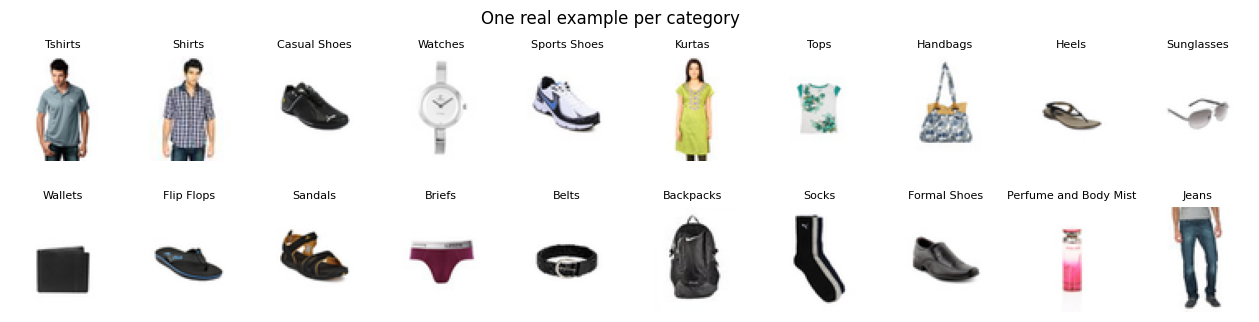

In [5]:
import numpy as np, matplotlib.pyplot as plt
d = np.load('data/fashion64.npz')
names = d['class_names']
fig, axes = plt.subplots(2, 10, figsize=(16, 3.6))
for c, ax in enumerate(axes.flat):
    i = np.where(d['labels'] == c)[0][0]
    ax.imshow(d['images'][i]); ax.set_title(names[c], fontsize=8); ax.axis('off')
plt.suptitle('One real example per category'); plt.show()

## 2. Train the baseline DCGAN

Same settings for both models: 40 epochs, batch 128, Adam (lr 2e-4, betas 0.5/0.999), seed 42.
Expect roughly 25-40 s per epoch on a T4. If Colab disconnects, just run the cell again.

In [6]:
!python -m src.train --model baseline --data data/fashion64.npz --out runs/baseline --epochs 40 --resume

device=cuda  images=33090  steps/epoch=258  model=baseline
Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/content/gan-mode-collapse/src/train.py", line 171, in <module>
    train(parse())
    ~~~~~^^^^^^^^^
  File "/content/gan-mode-collapse/src/train.py", line 81, in train
    torch.set_rng_state(ck["rng_cpu"])
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/torch/random.py", line 36, in set_rng_state
    default_generator.set_state(new_state)
    ~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^
TypeError: RNG state must be a torch.ByteTensor


## 3. Train the improved GAN (spectral normalization + hinge loss)

In [7]:
!python -m src.train --model improved --data data/fashion64.npz --out runs/improved --epochs 40 --resume

device=cuda  images=33090  steps/epoch=258  model=improved
[improved] epoch 1/40  loss_D=1.246  loss_G=0.633  diversity=38.48  (39s)
[improved] epoch 2/40  loss_D=1.750  loss_G=0.590  diversity=35.91  (40s)
[improved] epoch 3/40  loss_D=1.709  loss_G=0.676  diversity=37.73  (42s)
[improved] epoch 4/40  loss_D=1.618  loss_G=0.826  diversity=50.15  (41s)
[improved] epoch 5/40  loss_D=1.552  loss_G=0.841  diversity=54.48  (42s)
[improved] epoch 6/40  loss_D=1.408  loss_G=0.930  diversity=60.43  (42s)
[improved] epoch 7/40  loss_D=1.391  loss_G=0.913  diversity=59.15  (42s)
[improved] epoch 8/40  loss_D=1.360  loss_G=0.922  diversity=54.85  (42s)
[improved] epoch 9/40  loss_D=1.364  loss_G=0.881  diversity=56.36  (42s)
[improved] epoch 10/40  loss_D=1.370  loss_G=0.806  diversity=60.92  (42s)
[improved] epoch 11/40  loss_D=1.324  loss_G=0.838  diversity=57.44  (42s)
[improved] epoch 12/40  loss_D=1.343  loss_G=0.831  diversity=58.53  (42s)
[improved] epoch 13/40  loss_D=1.394  loss_G=0.781

Baseline, final epoch


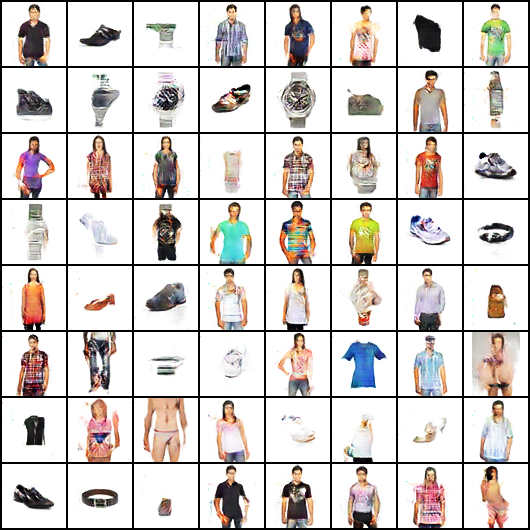

Improved, final epoch


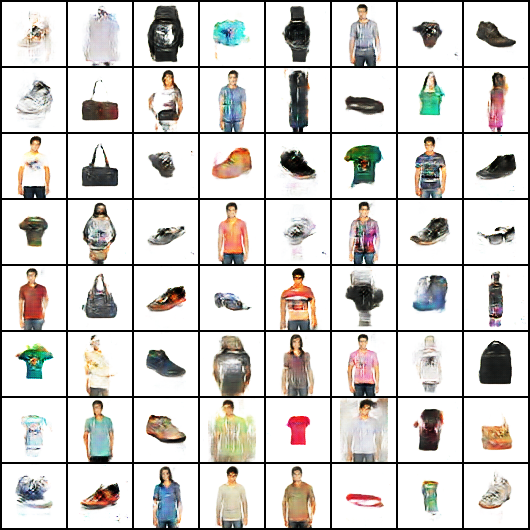

In [8]:
from IPython.display import Image, display
print('Baseline, final epoch'); display(Image('runs/baseline/samples/epoch_040.png'))
print('Improved, final epoch'); display(Image('runs/improved/samples/epoch_040.png'))

## 4. Train the category classifier (used only for evaluation and the demo filter)

In [9]:
import os
CLF_DRIVE = f'{DRIVE_DIR}/checkpoints/classifier.pt'
if not os.path.exists(CLF_DRIVE):
    !python -m src.classifier --data data/fashion64.npz --out "$CLF_DRIVE" --epochs 6
!cp "$CLF_DRIVE" checkpoints/classifier.pt

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 189MB/s]
epoch 1/6  train_acc=0.882  test_acc=0.912
epoch 2/6  train_acc=0.933  test_acc=0.933
epoch 3/6  train_acc=0.951  test_acc=0.933
epoch 4/6  train_acc=0.965  test_acc=0.942
epoch 5/6  train_acc=0.978  test_acc=0.946
epoch 6/6  train_acc=0.985  test_acc=0.948
Saved classifier to /content/drive/MyDrive/gan-mode-collapse/checkpoints/classifier.pt (test accuracy 0.948)


## 5. Benchmark both models

In [10]:
!python -m src.evaluate --data data/fashion64.npz \
    --baseline runs/baseline/G_final.pt --improved runs/improved/G_final.pt \
    --classifier checkpoints/classifier.pt --n 10000 --out results

Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100% 91.2M/91.2M [00:00<00:00, 133MB/s]
Extracting Inception features for real images ...

== baseline ==
  FID                              64.55
  precision                        0.0948
  recall                           0.1965
  categories_covered               18/20
  categories_covered_n             18
  KL_real_gen                      0.0663
  TVD_real_gen                     0.1175
  mean_classifier_confidence       0.7314
  latency_ms_per_img_bs1_cuda      0.48
  latency_ms_per_img_bs64_cuda     0.177
  latency_ms_per_img_bs1_cpu       7.334
  generator_params_M               3.58

== improved ==
  FID                              80.9
  precision                        0.1043
  recall                           0.1444
  categories_covered               12/20
  categories_cover

,baseline,improved
FID,64.55,80.9
precision,0.0948,0.1043
recall,0.1965,0.1444
categories_covered,18/20,12/20
categories_covered_n,18,12
KL_real_gen,0.0663,0.1804
TVD_real_gen,0.1175,0.2266
mean_classifier_confidence,0.7314,0.7076
latency_ms_per_img_bs1_cuda,0.48,0.509
latency_ms_per_img_bs64_cuda,0.177,0.173


side_by_side.png


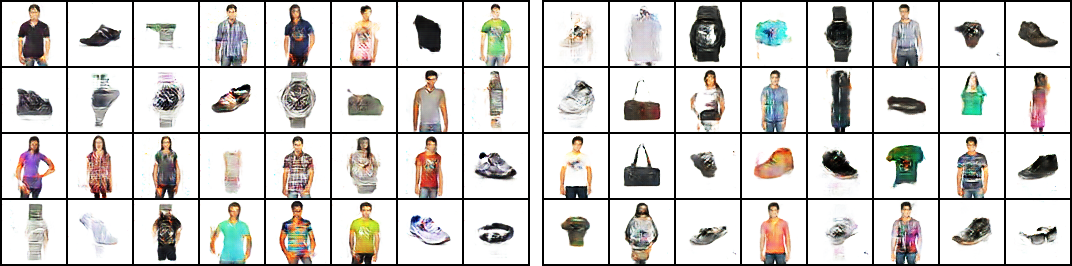

category_distribution.png


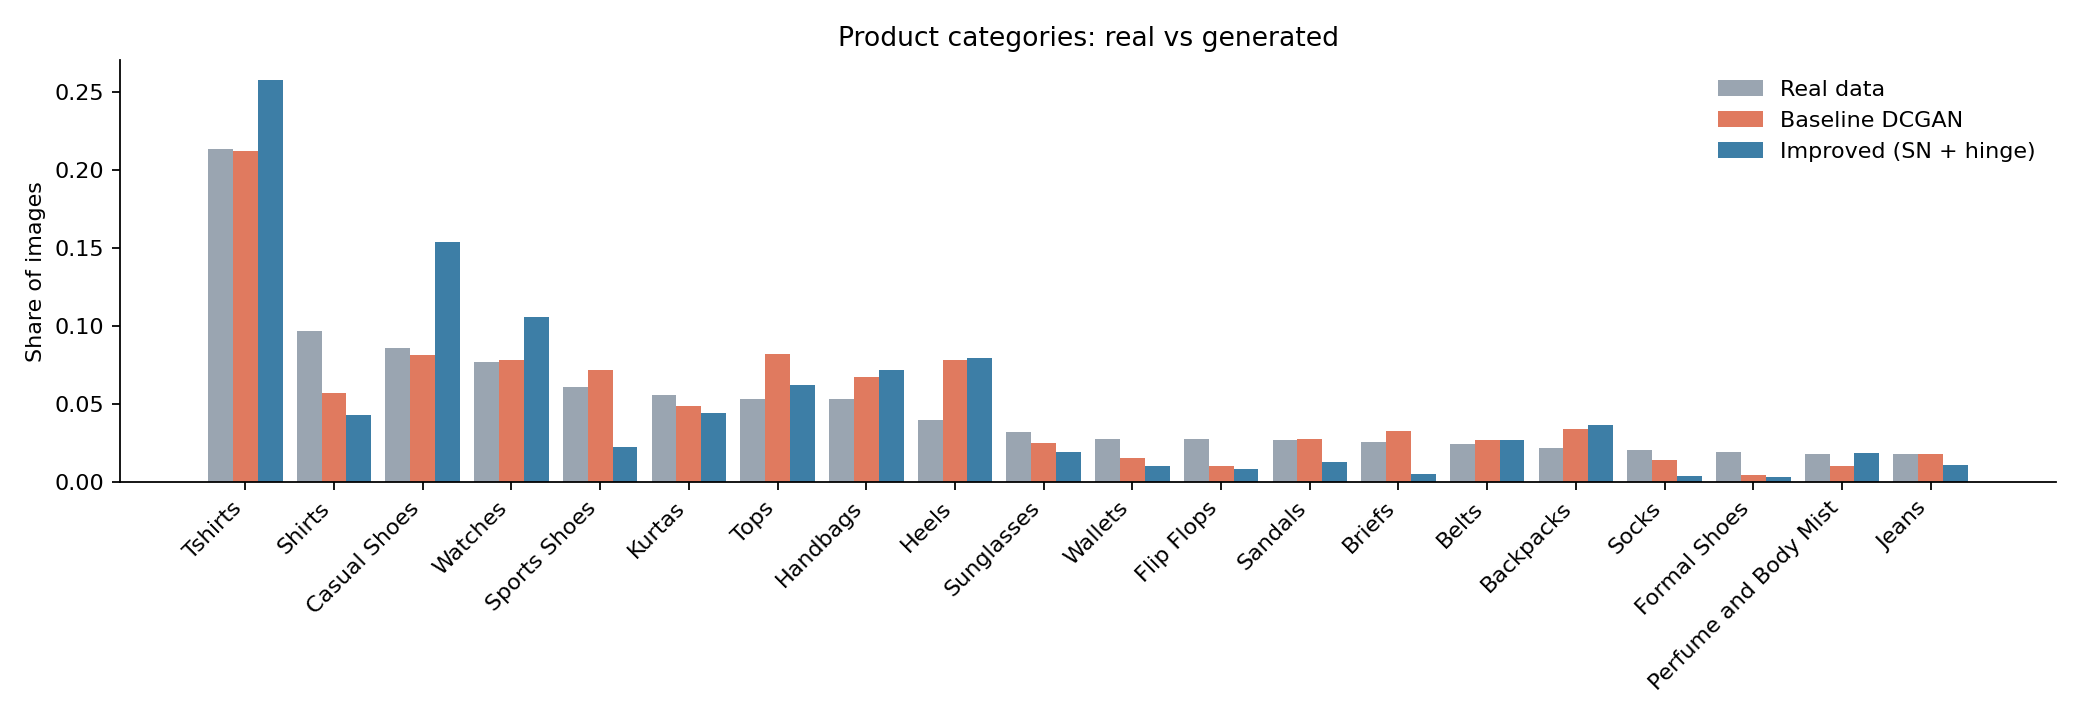

training_curves.png


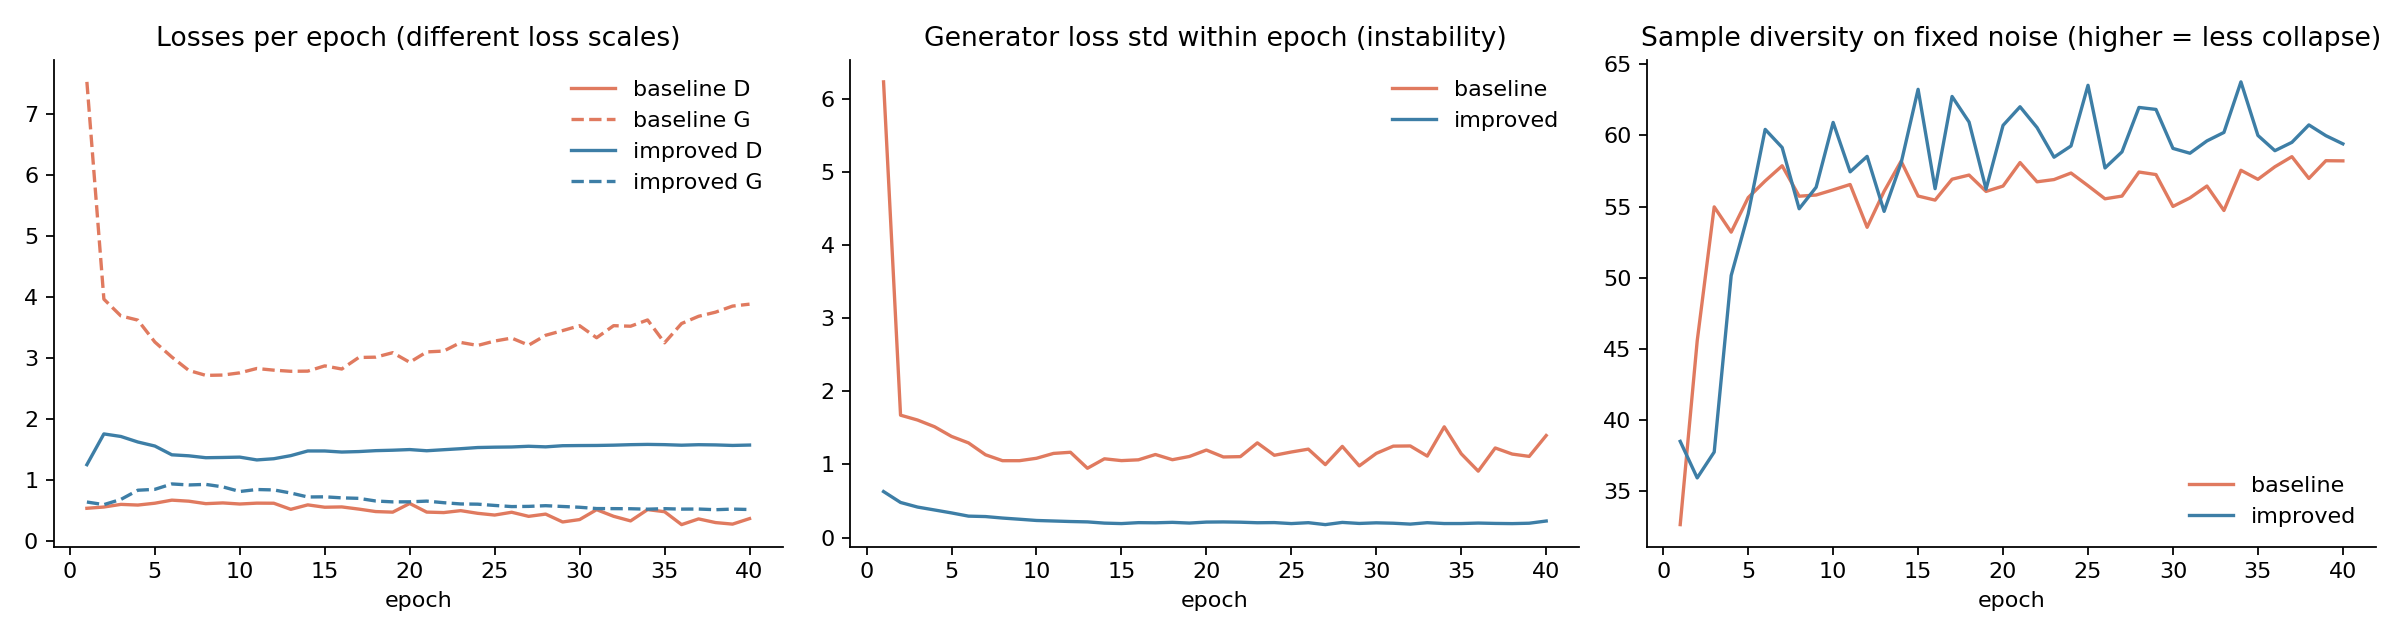

nearest_neighbours.png


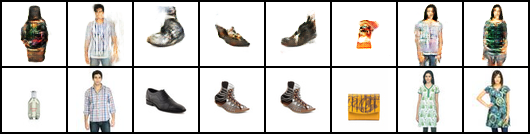

In [11]:
import pandas as pd
display(pd.read_csv('results/metrics.csv', index_col=0).T)
for f in ['side_by_side.png', 'category_distribution.png', 'training_curves.png', 'nearest_neighbours.png']:
    print(f); display(Image('results/' + f))

## 6. Copy the outputs into the repo for GitHub

This copies the final generator, classifier, results and sample grids into the repo folder and makes a zip you can download and push.

In [12]:
!cp runs/improved/G_final.pt checkpoints/G_improved.pt
!cp runs/baseline/G_final.pt checkpoints/G_baseline.pt
!mkdir -p results/training_logs results/samples
!cp runs/baseline/log.csv results/training_logs/baseline_log.csv
!cp runs/improved/log.csv results/training_logs/improved_log.csv
!cp data/fashion64_meta.json results/dataset_meta.json
!cp runs/baseline/samples/epoch_040.png results/samples/baseline_epoch40.png
!cp runs/improved/samples/epoch_040.png results/samples/improved_epoch40.png
!cp checkpoints/*.pt "$DRIVE_DIR"/checkpoints/
!cd /content && zip -qr gan-mode-collapse-outputs.zip gan-mode-collapse/checkpoints gan-mode-collapse/results
from google.colab import files
files.download('/content/gan-mode-collapse-outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Launch the demo (improved model only)
Click the public `gradio.live` link that appears below.

In [ ]:
!python app.py --generator checkpoints/G_improved.pt --classifier checkpoints/classifier.pt --share

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://9c85cd8e7e5768eb3d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
